## Membaca File Event.csv

In [65]:
import pandas as pd

data = pd.read_csv("data/events.csv")
data.head(5)

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


## Connection to Neo4j

In [66]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver("bolt://127.0.0.1:7687", auth=("neo4j", "Zenida2004"))
driver.verify_connectivity()

print("Berhasil terhubung ke Neo4j!")

Berhasil terhubung ke Neo4j!


/var/folders/44/z3ss0qj92jd0l22wd4xsj9br0000gn/T/ipykernel_73166/1694224761.py:4: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


In [67]:
with driver.session(database="neo4j") as session:
    result = session.run("RETURN 'Neo4j siap digunakan' AS status")
    print(result.single()["status"])

Neo4j siap digunakan


In [80]:
import os 
import sys

csv_file_path = os.path.join("data", "events.csv")

if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)

print(f"File ditemukan: {csv_file_path}")

File ditemukan: data/events.csv


### Create Constraint

In [9]:
def create_constraints(session):
    session.run(
        """
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorid IS UNIQUE
        """
    ).consume()

    session.run(
        """
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemid IS UNIQUE
        """
    ).consume()

    print("Constraints berhasil diperiksa/dibuat.")

In [78]:
with driver.session(database="neo4j") as session:
    create_constraints(session)

Constraints berhasil diperiksa/dibuat.


digunakan untuk membuat aturan agar ID setiap node Visitor dan Item di Neo4j bersifat unik.

### Import Batch

In [76]:

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorid: row.visitorid})
    MERGE (i:Item {itemid: row.itemid})
    WITH v, i, row

    CALL {
        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionid: row.transactionid
        }]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)


### Import Data

In [81]:

import tqdm
import math

batch_size = 5000

with driver.session(database="neo4j") as session:
    create_constraints(session)

    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    total_rows = sum(1 for _ in open(csv_file_path)) - 1
    total_chunks = math.ceil(total_rows / batch_size)
    print("Memulai proses impor data ke Neo4j...")

    for chunk in tqdm.tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        chunk["transactionid"] = (chunk["transactionid"].fillna("").astype(str))
        records = chunk.to_dict(orient="records")
        session.write_transaction(import_batch, records)

driver.close()
print("Proses impor berhasil.")

Constraints berhasil diperiksa/dibuat.
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 552/552 [02:01<00:00,  4.54it/s]

Proses impor berhasil.


## Soal 1

#### Melihat tanggal paling awal dan paling akhir pada dataset

In [ ]:
from neo4j import GraphDatabase
import pandas as pd

driver = GraphDatabase.driver("bolt://127.0.0.1:7687", auth=("neo4j", "Zenida2004"))
driver.verify_connectivity()

with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH ()-[r]->()
        WHERE r.timestamp IS NOT NULL
        RETURN
            min(r.timestamp) AS min_timestamp,
            max(r.timestamp) AS max_timestamp,
            count(r) AS total_events
    """)
    data = result.single()

tanggal_awal = data["min_timestamp"]
tanggal_maksimal = data["max_timestamp"]

print("Total event:", data["total_events"])
print("Tanggal awal:", pd.to_datetime(tanggal_awal, unit="ms", utc=True))
print("Tanggal akhir:", pd.to_datetime(tanggal_maksimal, unit="ms", utc=True))

/var/folders/44/z3ss0qj92jd0l22wd4xsj9br0000gn/T/ipykernel_73166/3159542967.py:13: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


Total event: 2756101
Tanggal awal: 2015-05-03 03:00:04.384000+00:00
Tanggal akhir: 2015-09-18 02:59:47.788000+00:00


Terdapat total event 2.756.101 dengan tanggal awal 3 Mei 2015 dan tanggal akhir 18 September 2015.

## Soal 2

#### Memfilter data interaksi berdasarkan timestamp dan simpan ke CSV.

In [82]:
import pandas as pd
import os

input_file = "data/events.csv"
output_dir = "data/filtered"
os.makedirs(output_dir, exist_ok=True)

p1_file = os.path.join(output_dir, "events_P1_training.csv")
p2_file = os.path.join(output_dir, "events_P2_testing.csv")

p1_awal = pd.Timestamp("2015-05-15", tz="UTC")
p1_akhir = pd.Timestamp("2015-08-04", tz="UTC")

p2_awal = pd.Timestamp("2015-08-04", tz="UTC")
p2_akhir = pd.Timestamp("2015-08-25", tz="UTC")

total_p1 = 0
total_p2 = 0

for chunk in pd.read_csv(input_file, chunksize=200_000):
    event_dates = pd.to_datetime(chunk["timestamp"], unit="ms", utc=True)

    mask_p1 = (event_dates >= p1_awal) & (event_dates < p1_akhir)
    mask_p2 = (event_dates >= p2_awal) & (event_dates < p2_akhir)

    if mask_p1.any():
        chunk.loc[mask_p1].to_csv(p1_file, mode="a", index=False, header=not os.path.exists(p1_file))
        total_p1 += mask_p1.sum()

    if mask_p2.any():
        chunk.loc[mask_p2].to_csv(p2_file, mode="a", index=False, header=not os.path.exists(p2_file))
        total_p2 += mask_p2.sum()

print("Jumlah event P1 training:", total_p1)
print("Jumlah event P2 testing:", total_p2)


Jumlah event P1 training: 1717044
Jumlah event P2 testing: 373717


Setelah menjalani proses fold untuk Data Training dan Testing, dengan Data Training yang dipilih adalah 15 Mei - 3 Agustus 2015 terdapat 1.717.044 jumlah interaksi. Serta pada Data Testing pada tanggal 4-24 Agustus 2015 terdapat 373.717 jumlah interaksi.

In [ ]:
def get_graph_composition(session, start_date, end_date):
    query = """
    MATCH (v:Visitor)-[r]->(i:Item)
    WHERE r.timestamp >= $start_ts
      AND r.timestamp < $end_ts
    RETURN
        type(r) AS relationship_type,
        count(r) AS total_relationships,
        count(DISTINCT v) AS total_visitors,
        count(DISTINCT i) AS total_items
    ORDER BY relationship_type
    """

    result = session.run(
        query,
        start_ts=int(pd.Timestamp(start_date, tz="UTC").timestamp() * 1000),
        end_ts=int(pd.Timestamp(end_date, tz="UTC").timestamp() * 1000)
    )

    return pd.DataFrame([record.data() for record in result])


with driver.session(database="neo4j") as session:
    p1_composition = get_graph_composition(
        session, "2015-05-15", "2015-08-04"
    )

    p2_composition = get_graph_composition(
        session, "2015-08-04", "2015-08-25"
    )

print("=== Komposisi Subgraf P1 (Training) ===")
display(p1_composition)

print("=== Komposisi Subgraf P2 (Testing) ===")
display(p2_composition)


=== Komposisi Subgraf P1 (Training) ===


,relationship_type,total_relationships,total_visitors,total_items
0,ADDED_TO_CART,42133,23116,17035
1,BOUGHT,13918,7270,8267
2,VIEWED,1660993,877402,191506


=== Komposisi Subgraf P2 (Testing) ===


,relationship_type,total_relationships,total_visitors,total_items
0,ADDED_TO_CART,9981,5555,5775
1,BOUGHT,3120,1682,2375
2,VIEWED,360616,212666,92260


Berdasarkan hasil komposisi subgraf, periode training (P1) memiliki 1.717.044 interaksi, sedangkan periode testing (P2) memiliki 373.717 interaksi. Pada kedua periode, relasi `VIEWED` merupakan jenis interaksi yang paling dominan, diikuti oleh `ADDED_TO_CART` dan `BOUGHT`. Hal ini menunjukkan bahwa aktivitas melihat produk jauh lebih sering terjadi dibandingkan aktivitas menambahkan produk ke keranjang maupun melakukan pembelian. Perbedaan jumlah interaksi antara P1 dan P2 juga menunjukkan bahwa data pada periode training lebih besar daripada data pada periode testing.

## Soal 3

In [22]:

def get_overall_composition(session, start_date, end_date):
    start_ts = int(
        pd.Timestamp(start_date, tz="UTC").timestamp() * 1000
    )
    end_ts = int(
        pd.Timestamp(end_date, tz="UTC").timestamp() * 1000
    )

    query = """
    MATCH (v:Visitor)-[r]->(i:Item)
    WHERE r.timestamp >= $start_ts
      AND r.timestamp < $end_ts
    RETURN
        count(r) AS total_interactions,
        count(DISTINCT v) AS unique_visitors,
        count(DISTINCT i) AS unique_items
    """

    record = session.run(
        query,
        start_ts=start_ts,
        end_ts=end_ts
    ).single()

    return record.data()


with driver.session(database="neo4j") as session:
    overall_p1 = get_overall_composition(
        session, "2015-05-15", "2015-08-04"
    )

    overall_p2 = get_overall_composition(
        session, "2015-08-04", "2015-08-25"
    )

composition_summary = pd.DataFrame([
    {"Periode": "P1 - Training", **overall_p1},
    {"Periode": "P2 - Testing", **overall_p2}
])

display(composition_summary)


,Periode,total_interactions,unique_visitors,unique_items
0,P1 - Training,1717044,879318,191682
1,P2 - Testing,373717,213262,92459


Berdasarkan hasil query komposisi subgraf, periode training (P1) terdiri atas 1.717.044 interaksi, 879.318 node Visitor unik, dan 191.682 node Item unik. Sementara itu, periode testing (P2) terdiri atas 373.717 interaksi, 213.262 node Visitor unik, dan 92.459 node Item unik. Jumlah tersebut diperoleh dengan memfilter relasi berdasarkan timestamp dan menghitung node unik menggunakan fungsi `count(DISTINCT)`. Hasil menunjukkan bahwa P1 memiliki jumlah interaksi, Visitor, dan Item yang lebih besar dibandingkan P2.

## Soal 4 

In [26]:
import pandas as pd
import numpy as np
from scipy.sparse import coo_matrix

# Membaca data training
events_p1 = pd.read_csv("data/filtered/events_P1_training.csv")

# Memberi indeks numerik untuk setiap Visitor dan Item
visitor_codes, visitor_ids = pd.factorize(events_p1["visitorid"])
item_codes, item_ids = pd.factorize(events_p1["itemid"])

# Membentuk matriks sparse Visitor × Item
user_item_matrix = coo_matrix(
    (
        np.ones(len(events_p1), dtype=np.int8),
        (visitor_codes, item_codes)
    ),
    shape=(len(visitor_ids), len(item_ids))
).tocsr()

# Mengubah interaksi berulang menjadi nilai biner 1
user_item_matrix.data[:] = 1
user_item_matrix.eliminate_zeros()

print("Jumlah baris data P1:", len(events_p1))
print("Jumlah Visitor unik:", len(visitor_ids))
print("Jumlah Item unik:", len(item_ids))
print("Dimensi matriks VSM User:", user_item_matrix.shape)
print("Jumlah pasangan Visitor-Item unik:", user_item_matrix.nnz)
print("Tipe matriks:", type(user_item_matrix))

Jumlah baris data P1: 1717044
Jumlah Visitor unik: 879318
Jumlah Item unik: 191682
Dimensi matriks VSM User: (879318, 191682)
Jumlah pasangan Visitor-Item unik: 1334999
Tipe matriks: <class 'scipy.sparse._csr.csr_matrix'>


Matriks berukuran 879.318 × 191.682 berarti setiap baris merepresentasikan satu Visitor unik, dan setiap kolom merepresentasikan satu Item unik.

Jumlah pasangan Visitor–Item unik lebih kecil daripada jumlah event karena seorang Visitor dapat berinteraksi dengan Item yang sama berkali-kali. Dalam matriks biner ini, interaksi berulang tersebut direpresentasikan sebagai satu nilai 1.

In [29]:
import networkx as nx
import matplotlib.pyplot as plt

# Hitung jumlah Item yang diinteraksikan oleh setiap Visitor
visitor_activity = np.asarray(
    user_item_matrix.sum(axis=1)
).ravel()

# Pilih 200 Visitor paling aktif untuk visualisasi
sample_size = 200
top_visitor_indices = np.argsort(visitor_activity)[-sample_size:]

# Ambil baris Visitor terpilih dari matriks VSM
sample_matrix = user_item_matrix[top_visitor_indices]

# Hitung jumlah Item yang sama untuk setiap pasangan Visitor
shared_items = sample_matrix @ sample_matrix.T

# Buat graf proyeksi User-User
G_user = nx.Graph()

for idx in top_visitor_indices:
    G_user.add_node(int(idx))

coo = shared_items.tocoo()

for i, j, weight in zip(coo.row, coo.col, coo.data):
    if i < j and weight > 0:
        G_user.add_edge(
            int(top_visitor_indices[i]),
            int(top_visitor_indices[j]),
            weight=int(weight)
        )

print("Jumlah node pada proyeksi User:", G_user.number_of_nodes())
print("Jumlah edge pada proyeksi User:", G_user.number_of_edges())
print("Jumlah komponen terhubung:", nx.number_connected_components(G_user))


Matplotlib is building the font cache; this may take a moment.


Jumlah node pada proyeksi User: 200
Jumlah edge pada proyeksi User: 11906
Jumlah komponen terhubung: 2


Artinya, graf sampel berisi 200 Visitor yang paling aktif. Terdapat 11.906 edge yang menghubungkan pasangan Visitor yang memiliki setidaknya satu Item yang sama. Graf terbagi menjadi dua komponen terhubung, yaitu dua kelompok node yang masing-masing saling terhubung melalui jalur graf, tanpa jalur penghubung di antara kedua kelompok tersebut.

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Hitung jumlah Item yang diinteraksikan oleh setiap Visitor
visitor_activity = np.asarray(
    user_item_matrix.sum(axis=1)
).ravel()

# Pilih 200 Visitor paling aktif untuk visualisasi
sample_size = 200
top_visitor_indices = np.argsort(visitor_activity)[-sample_size:]

# Ambil baris Visitor terpilih dari matriks VSM
sample_matrix = user_item_matrix[top_visitor_indices]

# Hitung jumlah Item yang sama untuk setiap pasangan Visitor
shared_items = sample_matrix @ sample_matrix.T

# Buat graf proyeksi User-User
G_user = nx.Graph()

for idx in top_visitor_indices:
    G_user.add_node(int(idx))

coo = shared_items.tocoo()

for i, j, weight in zip(coo.row, coo.col, coo.data):
    if i < j and weight > 0:
        G_user.add_edge(
            int(top_visitor_indices[i]),
            int(top_visitor_indices[j]),
            weight=int(weight)
        )

print("Jumlah node pada proyeksi User:", G_user.number_of_nodes())
print("Jumlah edge pada proyeksi User:", G_user.number_of_edges())
print("Jumlah komponen terhubung:", nx.number_connected_components(G_user))


Matplotlib is building the font cache; this may take a moment.


Jumlah node pada proyeksi User: 200
Jumlah edge pada proyeksi User: 11906
Jumlah komponen terhubung: 2


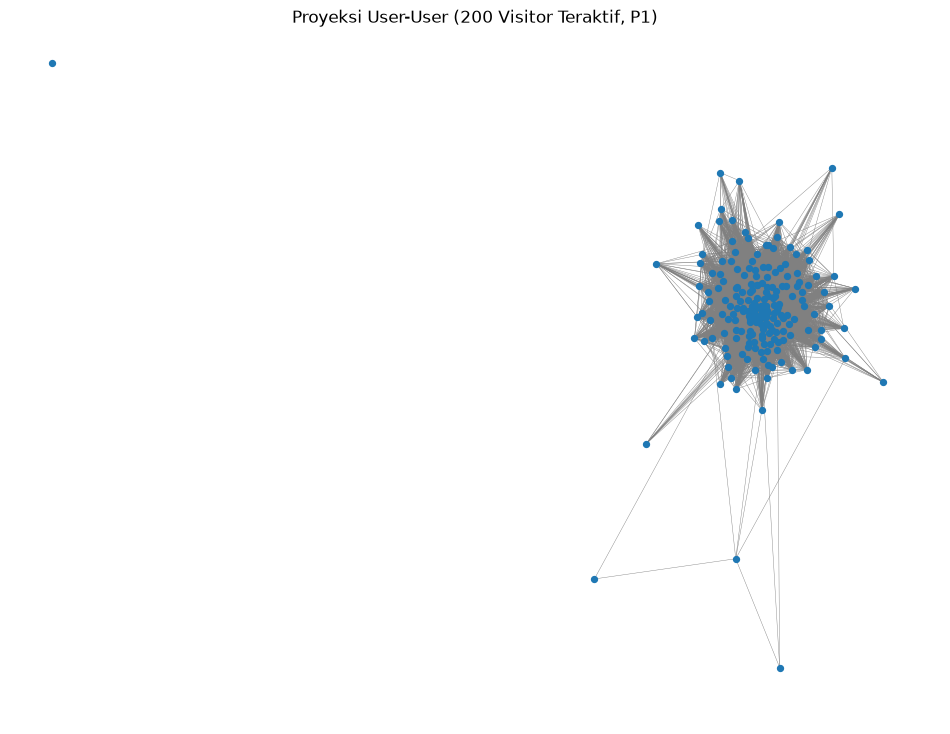

In [31]:

plt.figure(figsize=(12, 9))

pos = nx.spring_layout(
    G_user,
    seed=42,
    k=0.15,
    iterations=30
)

nx.draw_networkx(
    G_user,
    pos=pos,
    with_labels=False,
    node_size=18,
    width=0.3,
    edge_color="gray"
)

plt.title("Proyeksi User-User (200 Visitor Teraktif, P1)")
plt.axis("off")
plt.show()


## Soal 5

In [32]:

# Membalik orientasi matriks User-Item menjadi Item-User
item_user_matrix = user_item_matrix.transpose().tocsr()

print("Dimensi matriks VSM Item:", item_user_matrix.shape)
print("Jumlah Item unik:", item_user_matrix.shape[0])
print("Jumlah Visitor unik:", item_user_matrix.shape[1])
print("Jumlah pasangan Item-Visitor unik:", item_user_matrix.nnz)
print("Tipe matriks:", type(item_user_matrix))


Dimensi matriks VSM Item: (191682, 879318)
Jumlah Item unik: 191682
Jumlah Visitor unik: 879318
Jumlah pasangan Item-Visitor unik: 1334999
Tipe matriks: <class 'scipy.sparse._csr.csr_matrix'>


In [33]:

# Hitung jumlah Visitor unik yang berinteraksi dengan setiap Item
item_activity = np.asarray(
    item_user_matrix.sum(axis=1)
).ravel()

# Pilih 200 Item paling aktif
sample_size = 200
top_item_indices = np.argsort(item_activity)[-sample_size:]

# Ambil baris Item terpilih dari matriks VSM Item
sample_item_matrix = item_user_matrix[top_item_indices]

# Hitung jumlah Visitor yang sama untuk setiap pasangan Item
shared_visitors = sample_item_matrix @ sample_item_matrix.T

# Buat graf proyeksi Item-Item
G_item = nx.Graph()

for idx in top_item_indices:
    G_item.add_node(int(idx))

coo = shared_visitors.tocoo()

for i, j, weight in zip(coo.row, coo.col, coo.data):
    if i < j and weight > 0:
        G_item.add_edge(
            int(top_item_indices[i]),
            int(top_item_indices[j]),
            weight=int(weight)
        )

print("Jumlah node pada proyeksi Item:", G_item.number_of_nodes())
print("Jumlah edge pada proyeksi Item:", G_item.number_of_edges())
print("Jumlah komponen terhubung:", nx.number_connected_components(G_item))


Jumlah node pada proyeksi Item: 200
Jumlah edge pada proyeksi Item: 8781
Jumlah komponen terhubung: 6


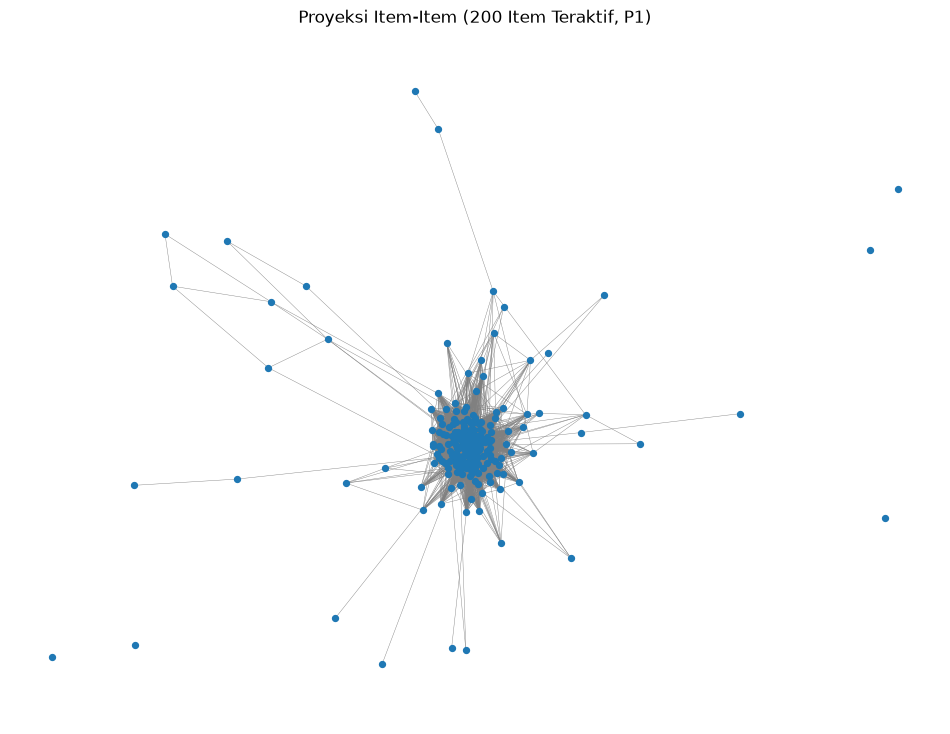

In [34]:

plt.figure(figsize=(12, 9))

pos_item = nx.spring_layout(
    G_item,
    seed=42,
    k=0.15,
    iterations=30
)

nx.draw_networkx(
    G_item,
    pos=pos_item,
    with_labels=False,
    node_size=18,
    width=0.3,
    edge_color="gray"
)

plt.title("Proyeksi Item-Item (200 Item Teraktif, P1)")
plt.axis("off")
plt.show()


## Soal 6 

Untuk tahap analisis similarity selanjutnya, kita bisa memilih proyeksi Item–Item sebagai pilihan awal karena jumlah Item unik secara keseluruhan lebih sedikit daripada jumlah Visitor, dan pada sampel 200 node proyeksi Item juga menghasilkan lebih sedikit edge.

Namun, ada batasan penting: sampel yang dibandingkan terdiri atas 200 Visitor teraktif dan 200 Item teraktif, sehingga hasil ini belum membuktikan bahwa proyeksi Item pasti lebih efisien pada keseluruhan graf. Kesimpulan tersebut sebaiknya ditulis sebagai pilihan berdasarkan karakteristik data dan hasil sampel.

## Soal 7

In [36]:

# Pilih Item dengan jumlah Visitor unik terbanyak sebagai acuan
reference_idx = int(top_item_indices[-1])
reference_item_id = int(item_ids[reference_idx])

# Hitung jumlah Visitor untuk setiap Item
item_norms = np.sqrt(
    np.asarray(item_user_matrix.multiply(item_user_matrix).sum(axis=1))
    .ravel()
)

# Hitung irisan Visitor antara Item acuan dan Item lainnya
dot_products = (
    item_user_matrix.getrow(reference_idx) @ item_user_matrix.T
).toarray().ravel()

# Hitung cosine similarity
denominator = item_norms[reference_idx] * item_norms
similarities = np.divide(
    dot_products,
    denominator,
    out=np.zeros_like(dot_products, dtype=float),
    where=denominator != 0
)

# Urutkan dari similarity tertinggi, kecuali Item acuan sendiri
similarities[reference_idx] = -1
top5_indices = np.argsort(similarities)[-5:][::-1]

top5_similar_items = pd.DataFrame({
    "reference_item_id": reference_item_id,
    "similar_item_id": [int(item_ids[i]) for i in top5_indices],
    "cosine_similarity": [float(similarities[i]) for i in top5_indices]
})

print("Item acuan:", reference_item_id)
display(top5_similar_items)


Item acuan: 5411


,reference_item_id,similar_item_id,cosine_similarity
0,5411,33030,0.144373
1,5411,33956,0.084532
2,5411,358234,0.081491
3,5411,375492,0.065957
4,5411,459936,0.062732


Item 33030 memiliki nilai cosine similarity tertinggi terhadap Item 5411, yaitu 0,144373. Artinya, di antara lima Item tersebut, Item 33030 memiliki pola interaksi Visitor yang paling mirip dengan Item acuan. Nilai similarity ini didasarkan pada pola Visitor yang sama-sama berinteraksi dengan Item, bukan pada kemiripan nama atau kategori produknya.

## (a) 

In [37]:

# Ubah tabel hasil similarity menjadi list of dictionaries
similarity_records = top5_similar_items.to_dict(orient="records")

# Simpan similarity sebagai relasi baru di Neo4j
save_similarity_query = """
UNWIND $rows AS row
MATCH (source:Item {itemid: row.reference_item_id})
MATCH (target:Item {itemid: row.similar_item_id})
MERGE (source)-[r:SIMILAR_TO]->(target)
SET r.similarity = row.cosine_similarity
RETURN
    source.itemid AS reference_item,
    target.itemid AS similar_item,
    r.similarity AS cosine_similarity
ORDER BY cosine_similarity DESC
"""

with driver.session(database="neo4j") as session:
    saved_results = session.run(
        save_similarity_query,
        rows=similarity_records
    )
    saved_similarity = pd.DataFrame(
        [record.data() for record in saved_results]
    )

display(saved_similarity)


,reference_item,similar_item,cosine_similarity
0,5411,33030,0.144373
1,5411,33956,0.084532
2,5411,358234,0.081491
3,5411,375492,0.065957
4,5411,459936,0.062732


In [38]:

top5_query = """
MATCH (source:Item {itemid: 5411})-[r:SIMILAR_TO]->(target:Item)
RETURN
    source.itemid AS reference_item,
    target.itemid AS similar_item,
    r.similarity AS cosine_similarity
ORDER BY cosine_similarity DESC
LIMIT 5
"""

with driver.session(database="neo4j") as session:
    result = session.run(top5_query)
    top5_from_neo4j = pd.DataFrame(
        [record.data() for record in result]
    )

display(top5_from_neo4j)


,reference_item,similar_item,cosine_similarity
0,5411,33030,0.144373
1,5411,33956,0.084532
2,5411,358234,0.081491
3,5411,375492,0.065957
4,5411,459936,0.062732


# 2.2 Analytics

## Soal 1

In [58]:

import pandas as pd
import numpy as np

# Membaca data training dan testing
events_p1 = pd.read_csv("data/filtered/events_P1_training.csv")
events_p2 = pd.read_csv("data/filtered/events_P2_testing.csv")

# Mengambil daftar user unik pada masing-masing periode
users_p1 = set(events_p1["visitorid"].unique())
users_p2 = set(events_p2["visitorid"].unique())

# Menghitung jumlah item unik yang diinteraksikan setiap user di P1
items_per_user = events_p1.groupby("visitorid")["itemid"].nunique()

# Menentukan user dengan minimal 5 item unik di training
active_users = set(items_per_user[items_per_user >= 5].index)

# Kandidat harus muncul di training dan testing
eligible_users = sorted(
    active_users.intersection(users_p1).intersection(users_p2)
)

# Memilih satu user secara acak dengan seed tetap
random_seed = 42
rng = np.random.RandomState(random_seed)
selected_user = int(rng.choice(eligible_users))

print("Random seed:", random_seed)
print("Jumlah user P1:", len(users_p1))
print("Jumlah user P2:", len(users_p2))
print("Jumlah kandidat yang memenuhi syarat:", len(eligible_users))
print("User terpilih:", selected_user)
print("Jumlah item unik pada training:",
      int(items_per_user.loc[selected_user]))


Random seed: 42
Jumlah user P1: 879318
Jumlah user P2: 213262
Jumlah kandidat yang memenuhi syarat: 2225
User terpilih: 547162
Jumlah item unik pada training: 5


In [60]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix

# Memetakan ID user dan item ke indeks matriks
user_to_idx = {user_id: idx for idx, user_id in enumerate(visitor_ids)}
item_to_idx = {item_id: idx for idx, item_id in enumerate(item_ids)}

# Indeks user target
target_idx = user_to_idx[selected_user]


knn = NearestNeighbors(
    n_neighbors=6,
    metric="cosine",
    algorithm="brute"
)
knn.fit(user_item_matrix)

distances, indices = knn.kneighbors(
    user_item_matrix[target_idx],
    n_neighbors=6
)

neighbors = [
    (idx, distance)
    for idx, distance in zip(indices[0], distances[0])
    if idx != target_idx
][:5]

recommendation_scores = {}

for neighbor_idx, distance in neighbors:
    similarity = 1 - distance

    for item_idx in user_item_matrix[neighbor_idx].indices:
        if item_idx not in target_items:
            recommendation_scores[item_idx] = (
                recommendation_scores.get(item_idx, 0)
                + similarity
            )

ranked_items = sorted(
    recommendation_scores.items(),
    key=lambda x: x[1],
    reverse=True
)

top5_recommendations = pd.DataFrame({
    "itemid": [int(item_ids[idx]) for idx, score in ranked_items[:5]],
    "recommendation_score": [score for idx, score in ranked_items[:5]]
})

print("User target:", selected_user)
print("Jumlah tetangga:", len(neighbors))
print("Jumlah kandidat item baru:", len(recommendation_scores))
display(top5_recommendations)


User target: 547162
Jumlah tetangga: 5
Jumlah kandidat item baru: 3


,itemid,recommendation_score
0,241752,3.046220
1,223003,3.046220
2,127042,0.516398


## Soal 2

In [61]:

# Mengambil item aktual user pada periode testing P2
actual_items = set(
    events_p2.loc[
        events_p2["visitorid"] == selected_user,
        "itemid"
    ].unique()
)

# Lima rekomendasi teratas yang tersedia
recommended_items = top5_recommendations["itemid"].tolist()

# Relevansi: 1 jika item direkomendasikan memang muncul di P2
hits = [
    1 if item in actual_items else 0
    for item in recommended_items
]

# Hit@5: apakah setidaknya ada satu item relevan?
hit_at_5 = int(sum(hits) > 0)

# DCG@5
dcg_at_5 = sum(
    rel / np.log2(rank + 1)
    for rank, rel in enumerate(hits, start=1)
)

# IDCG@5
ideal_hits = min(len(actual_items), 5)
idcg_at_5 = sum(
    1 / np.log2(rank + 1)
    for rank in range(1, ideal_hits + 1)
)

# NDCG@5
ndcg_at_5 = dcg_at_5 / idcg_at_5 if idcg_at_5 > 0 else 0.0

print("User target:", selected_user)
print("Jumlah item aktual di P2:", len(actual_items))
print("Item aktual:", sorted(actual_items))
print("Item rekomendasi:", recommended_items)
print("Relevansi tiap item:", hits)
print("Hit@5:", hit_at_5)
print("NDCG@5:", round(ndcg_at_5, 4))


User target: 547162
Jumlah item aktual di P2: 4
Item aktual: [np.int64(123554), np.int64(346300), np.int64(363290), np.int64(413424)]
Item rekomendasi: [241752, 223003, 127042]
Relevansi tiap item: [0, 0, 0]
Hit@5: 0
NDCG@5: 0.0


In [62]:

# Item aktual user target pada periode testing
actual_items = set(
    events_p2.loc[
        events_p2["visitorid"] == selected_user,
        "itemid"
    ].unique()
)

print("User target:", selected_user)
print("Item aktual P2:", sorted(actual_items))

print("\nItem dari masing-masing tetangga yang juga muncul di P2:")

for neighbor_idx, distance in neighbors:
    neighbor_id = visitor_ids[neighbor_idx]
    neighbor_items = set(user_item_matrix[neighbor_idx].indices)

    # Konversi indeks matriks kembali ke item ID asli
    neighbor_item_ids = {item_ids[idx] for idx in neighbor_items}
    overlap = neighbor_item_ids.intersection(actual_items)

    print(
        "Visitor:", neighbor_id,
        "| Similarity:", round(1 - distance, 4),
        "| Item aktual yang dimiliki di P1:", sorted(overlap)
    )


User target: 547162
Item aktual P2: [np.int64(123554), np.int64(346300), np.int64(363290), np.int64(413424)]

Item dari masing-masing tetangga yang juga muncul di P2:
Visitor: 845079 | Similarity: 0.6325 | Item aktual yang dimiliki di P1: []
Visitor: 647220 | Similarity: 0.6325 | Item aktual yang dimiliki di P1: []
Visitor: 1049493 | Similarity: 0.6325 | Item aktual yang dimiliki di P1: []
Visitor: 835934 | Similarity: 0.6325 | Item aktual yang dimiliki di P1: []
Visitor: 969217 | Similarity: 0.5164 | Item aktual yang dimiliki di P1: []


In [63]:

# Ground truth dari data testing P2
actual_items = set(
    events_p2.loc[
        events_p2["visitorid"] == selected_user,
        "itemid"
    ].unique()
)

# Tiga item hasil rekomendasi KNN
recommended_items = top5_recommendations["itemid"].tolist()

# Relevansi setiap item rekomendasi
relevance = [
    int(item in actual_items)
    for item in recommended_items
]

# Hit@5: bernilai 1 jika ada setidaknya satu item relevan
hit_at_5 = int(any(relevance[:5]))

# DCG@5
dcg_at_5 = sum(
    rel / np.log2(rank + 1)
    for rank, rel in enumerate(relevance[:5], start=1)
)

# IDCG@5 berdasarkan jumlah item relevan aktual
ideal_relevant = min(len(actual_items), 5)

idcg_at_5 = sum(
    1 / np.log2(rank + 1)
    for rank in range(1, ideal_relevant + 1)
)

ndcg_at_5 = dcg_at_5 / idcg_at_5 if idcg_at_5 > 0 else 0.0

print("User target:", selected_user)
print("Rekomendasi:", recommended_items)
print("Item aktual P2:", sorted(actual_items))
print("Relevansi:", relevance)
print("Hit@5:", hit_at_5)
print("NDCG@5:", round(ndcg_at_5, 4))


User target: 547162
Rekomendasi: [241752, 223003, 127042]
Item aktual P2: [np.int64(123554), np.int64(346300), np.int64(363290), np.int64(413424)]
Relevansi: [0, 0, 0]
Hit@5: 0
NDCG@5: 0.0


Berdasarkan hasil rekomendasi menggunakan User-Based KNN dengan \(k=5\), diperoleh tiga item rekomendasi untuk user 547162, yaitu item 241752, 223003, dan 127042. Evaluasi dilakukan dengan membandingkan item rekomendasi terhadap interaksi aktual user pada periode testing P2. Hasil menunjukkan bahwa tidak terdapat item rekomendasi yang sesuai dengan interaksi aktual, sehingga diperoleh nilai Hit@5 sebesar 0 dan NDCG@5 sebesar 0,0000. Hasil ini menunjukkan bahwa rekomendasi yang dihasilkan belum mampu menemukan item relevan bagi user tersebut pada periode pengujian.